In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train_raw = pd.read_csv("../Project_data/train.csv")  
print(train_raw.shape)

(6534, 40)


In [2]:
train_raw.head(5)

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


**Nota:** esta limpeza é só para as features novas não darem erro (as 65 linhas sem data, os sentinels do `spend_365d` e os −4 dias passam a NaN).

In [3]:
df = train_raw.dropna(subset=["purchase_date"]).copy()      # as 65 linhas vazias
df["purchase_date"] = pd.to_datetime(df["purchase_date"])

# valores impossíveis → NaN (regras do PDF, secções 6.1 e 6.3)
df.loc[(df["spend_365d"] >= 1e9) | (df["spend_365d"] < 0), "spend_365d"] = np.nan
for col in ["prior_mean_gap_days", "days_since_previous_purchase"]:
    df.loc[df[col] < 0, col] = np.nan                        # os −4 dias

print(df.shape)

(6469, 40)


## Which total does the purchase history use?

Some features compare the current purchase with the customer's history, so both must use the same measure. For customers with exactly one previous purchase, `prior_total_spend` should equal the previous purchase's total.

In [4]:
# Does the purchase history use "Total Liquido" or "Total a Pagar"?
t = df.sort_values(["customer_id", "purchase_date"])
prev_net = t.groupby("customer_id")["Total Liquido"].shift()
prev_pay = t.groupby("customer_id")["Total a Pagar"].shift()
m = t["prior_purchase_count"] == 1

print("History = Total Liquido:", (abs(t.loc[m, "prior_total_spend"] - prev_net[m]) < 0.01).mean().round(3))
print("History = Total a Pagar:", (abs(t.loc[m, "prior_total_spend"] - prev_pay[m]) < 0.01).mean().round(3))

History = Total Liquido: 0.063
History = Total a Pagar: 0.993


The history is measured with `Total a Pagar` (VAT and shipping included): it matches in 99.3% of the cases, against 6.3% for `Total Liquido`.

## Engineered features


| Feature | Formula | What it measures | How to read it |
|---|---|---|---|
| `recency_ratio` | days since previous purchase / customer's mean gap between purchases | Whether the customer is late compared to their usual rhythm | 1 = on rhythm, >1 = late |
| `purchases_per_year` | number of previous purchases / tenure in years | How intensely the customer buys | Higher = more active customer |
| `value_vs_usual` | purchase value / mean value of previous purchases | Whether this purchase is larger or smaller than usual | >1 = larger than usual |
| `recent_count_share` | purchases in the last 90 days / purchases in the last year | Whether purchase frequency is increasing or decreasing | ~0.25 = steady pace, close to 1 = speeding up, 0 = stopped |
| `discount_pct` | line discount / gross total | Discount as a share of the purchase value | 0.20 = 20% discount |
| `value_per_line` | purchase value / number of invoice lines | Whether the purchase has a few expensive items or many cheap ones | Higher = higher-value lines |
| `value_cv` | std / mean of previous purchase values | Whether the customer always spends similar amounts | Close to 0 = orders always similar |
| `has_shipping` | shipping costs > 0 | Whether the order was delivered | 1 = had shipping costs |

Denominators equal to 0 are set to `NaN` before dividing, so no infinite values appear. The remaining `NaN`s (e.g. customers without enough previous purchases) are left for the preprocessing to handle.

In [5]:
def add_engineered_features(df: pd.DataFrame) -> pd.DataFrame:
    """New features computed row by row. Fixed formulas only: nothing is learned from the data."""
    out = df.copy()

    # Customer's average past purchase value, from total / count (fewer gaps than prior_mean_purchase_value).
    # The purchase history is measured with "Total a Pagar" (VAT and shipping included).
    count = out["prior_purchase_count"].where(out["prior_purchase_count"] > 0)
    mean_value = (out["prior_total_spend"] / count).where(lambda s: s > 0)

    # 1. Delay relative to the customer's usual purchase rhythm (1 = on rhythm, >1 = late)
    gap = out["prior_mean_gap_days"].where(out["prior_mean_gap_days"] > 0)
    out["recency_ratio"] = out["days_since_previous_purchase"] / gap

    # 2. Purchases per year of tenure (minimum of 30 days to avoid huge values for very new customers)
    tenure_years = out["customer_tenure_days"].clip(lower=30) / 365
    out["purchases_per_year"] = out["prior_purchase_count"] / tenure_years

    # 3. Current purchase vs. the customer's average purchase value (>1 = larger than usual)
    #    "Total a Pagar" so that both sides use the same measure as the history
    out["value_vs_usual"] = out["Total a Pagar"] / mean_value

    # 4. Share of last year's purchases made in the last 90 days (~0.25 = steady pace)
    count_365 = out["purchase_count_365d"].where(out["purchase_count_365d"] > 0)
    out["recent_count_share"] = out["purchase_count_90d"] / count_365

    # 5. Line discount as a share of the gross value
    gross = out["Total Bruto"].where(out["Total Bruto"] > 0)
    out["discount_pct"] = out["Total Desc_ Linha"] / gross

    # 6. Average value per invoice line (few expensive lines vs. many cheap ones)
    lines = out["N_ Detalhes"].where(out["N_ Detalhes"] > 0)
    out["value_per_line"] = out["Total Liquido"] / lines

    # 7. Consistency of past purchase values (close to 0 = orders always similar)
    out["value_cv"] = out["prior_std_purchase_value"] / mean_value

    # 8. Whether the order had shipping costs (i.e. was delivered)
    out["has_shipping"] = (out["Total Portes"] > 0).astype(int)

    return out


df_fe = add_engineered_features(df)

new_features = [
    "recency_ratio", "purchases_per_year", "value_vs_usual", "recent_count_share",
    "discount_pct", "value_per_line", "value_cv", "has_shipping",
]

In [6]:
# Target-based exploration only on development years: the 2024 holdout (and 2025) stay untouched
df_dev = df_fe[df_fe["purchase_date"].dt.year < 2024].copy()
print(df_dev.shape)

(5634, 48)


## Sanity checks

No infinite values should appear, and the shares (`recent_count_share`, `discount_pct`) must stay between 0 and 1. These checks do not use the target, so they run on all rows.

In [7]:
# Sanity checks on the new features
print(df_fe[new_features].describe().T.round(3))
print("\nNaN per feature:\n", df_fe[new_features].isna().sum())
print("\nInfinite values:", np.isinf(df_fe[new_features]).sum().sum())           
print("recent_count_share > 1:", (df_fe["recent_count_share"] > 1).sum())    
print("discount_pct > 1:", (df_fe["discount_pct"] > 1).sum())                   

                     count    mean      std    min     25%     50%     75%  \
recency_ratio       5031.0   1.500    8.207  0.001   0.337   0.831   1.502   
purchases_per_year  6469.0   7.940   11.635  0.000   2.607   4.594   7.825   
value_vs_usual      5866.0   1.220    1.852  0.002   0.367   0.833   1.545   
recent_count_share  5626.0   0.251    0.284  0.000   0.000   0.200   0.333   
discount_pct        6469.0   0.110    0.135  0.000   0.000   0.046   0.200   
value_per_line      6469.0  89.495  280.985  0.108  17.654  30.109  55.220   
value_cv            5421.0   0.847    0.336  0.000   0.638   0.824   1.004   
has_shipping        6469.0   0.163    0.369  0.000   0.000   0.000   0.000   

                         max  
recency_ratio        478.667  
purchases_per_year    75.147  
value_vs_usual        68.257  
recent_count_share     1.000  
discount_pct           0.975  
value_per_line      8780.000  
value_cv               2.854  
has_shipping           1.000  

NaN per feature:


No infinite values, and the two shares (`recent_count_share`, `discount_pct`) stay between 0 and 1, as proportions should. The NaNs in `value_vs_usual` (603) and `value_cv` (1,048) are all structural: they need at least 1 and 2 previous purchases. Computing the customer's mean as `prior_total_spend / prior_purchase_count`, instead of using `prior_mean_purchase_value`, avoids that column's unexpected gaps (as the preprocessing document also does). `recent_count_share` is missing for the 843 rows with no purchases in the last year. `recency_ratio` (1,438) is mostly structural (fewer than 2 previous purchases), plus a few unexpected gaps in `prior_mean_gap_days` and the −4 day gaps set to NaN. 

## Distributions of the new features

We start by looking at the distribution of each new feature, split by target class (repeat vs. no repeat), to see its shape and whether the two classes behave differently. Densities are used so both classes are comparable despite their different sizes, and long-tailed features are plotted up to the 99th percentile (for readability only: the data is not changed). Only purchases before 2024 are used, so the holdout is not involved in any decision.

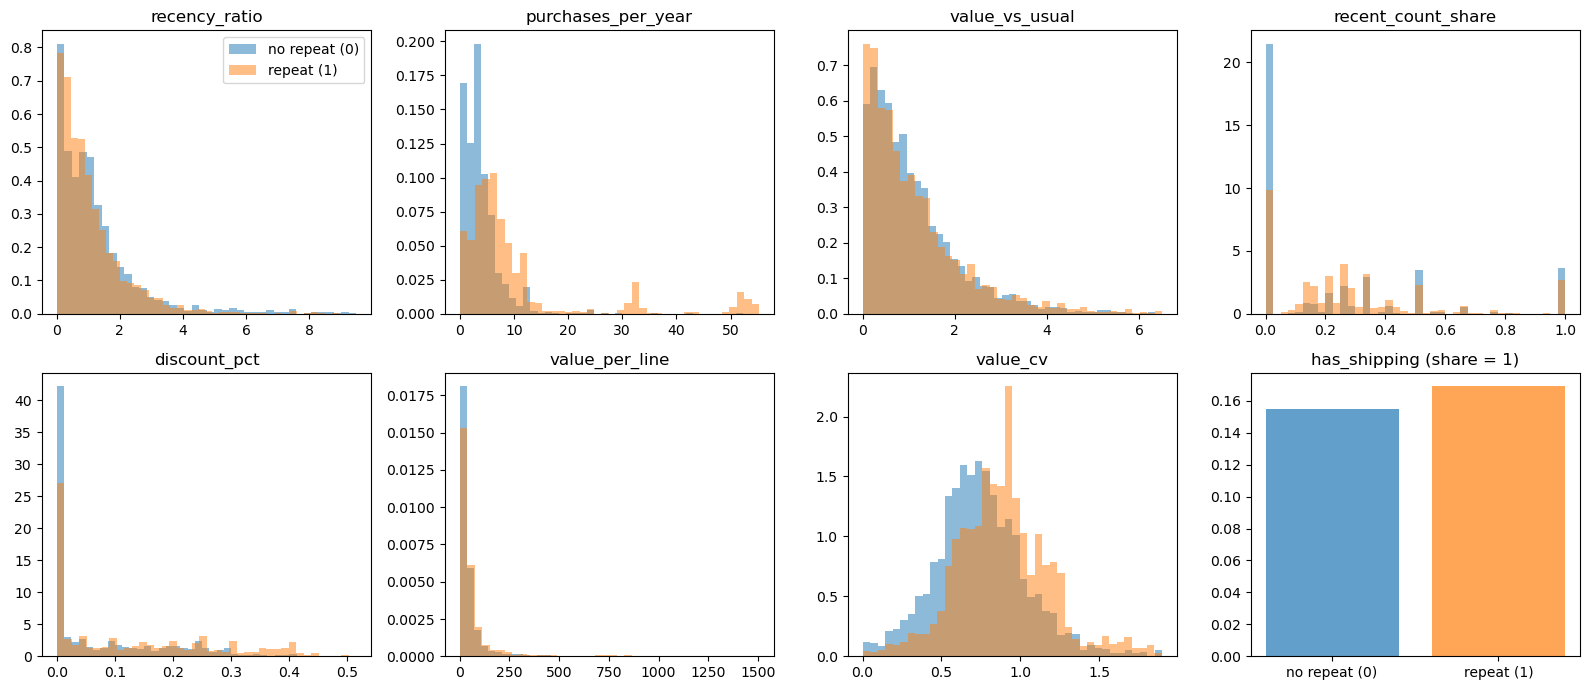

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for ax, col in zip(axes.flat, new_features):
    data = df_fe[[col, "repeat_purchase_90d"]].dropna()

    if col == "has_shipping":
        # Binary feature: share of orders with shipping in each class
        share = data.groupby("repeat_purchase_90d")[col].mean()
        ax.bar(["no repeat (0)", "repeat (1)"], share.values, color=["tab:blue", "tab:orange"], alpha=0.7)
        ax.set_title(f"{col} (share = 1)")
        continue

    upper = data[col].quantile(0.99)                      # plot up to p99 (display only)
    for target, color, label in [(0, "tab:blue", "no repeat (0)"), (1, "tab:orange", "repeat (1)")]:
        values = data.loc[data["repeat_purchase_90d"] == target, col]
        ax.hist(values[values <= upper], bins=40, density=True, alpha=0.5, color=color, label=label)
    ax.set_title(f"{col}")

axes.flat[0].legend()
plt.tight_layout()
plt.show()

Some features are very skewed: `recency_ratio`, `purchases_per_year`, `value_vs_usual` and `value_per_line` have long right tails, so most values are squeezed next to 0 and the plots are hard to read. To see their shape and compare the classes better, we plot them on a log scale, using log(1 + x) because some of these features contain zeros (log(0) is undefined).

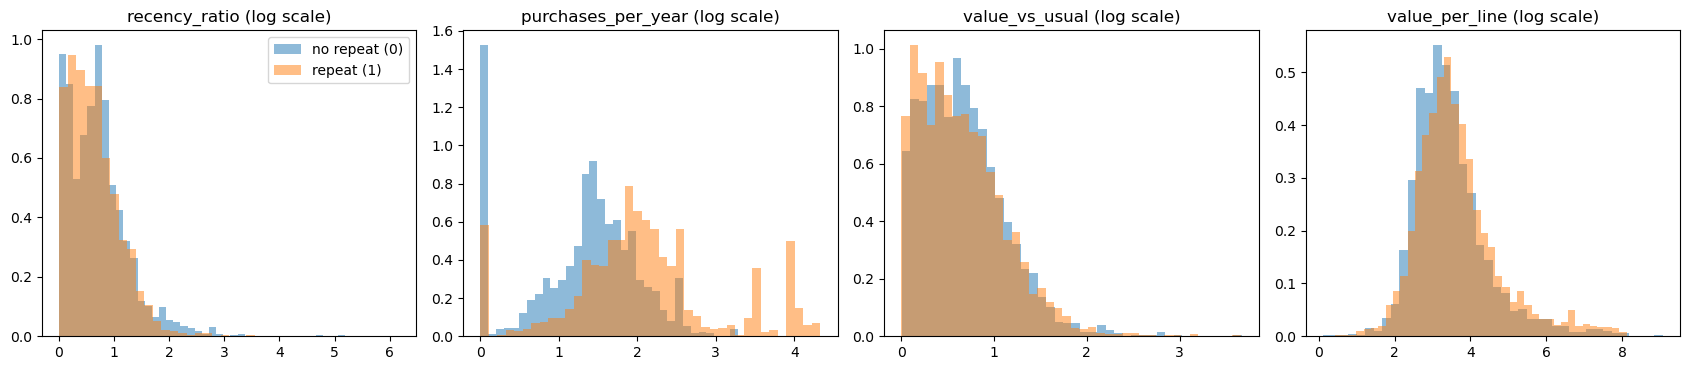

In [9]:
skewed = ["recency_ratio", "purchases_per_year", "value_vs_usual", "value_per_line"]

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, col in zip(axes, skewed):
    data = df_dev[[col, "repeat_purchase_90d"]].dropna()
    for target, color, label in [(0, "tab:blue", "no repeat (0)"), (1, "tab:orange", "repeat (1)")]:
        values = data.loc[data["repeat_purchase_90d"] == target, col]
        ax.hist(np.log1p(values), bins=40, density=True, alpha=0.5, color=color, label=label)
    ax.set_title(f"{col} (log scale)")
axes[0].legend()
plt.tight_layout()
plt.show()

### Conclusions from the distributions

**Overall:** the features that describe *how often and how recently* the customer buys separate the two classes best, while the features based on *purchase values* show little difference. This matches the EDA, where purchase frequency and recency were the strongest signals.

**Feature by feature:**

| Signal | Feature | What the plots show |
|---|---|---|
| **Strong** | `purchases_per_year` | The clearest separation. Non-repeaters concentrate around 2–5 purchases per year, plus a spike at 0 (first purchases). Repeaters are shifted to about 3.5–19 per year, and the very frequent customers (about 30–50 per year) are almost all repeaters. |
| **Strong** | `recent_count_share` | The spike at 0 (no purchases in the last 90 days) is mostly non-repeaters, while repeaters spread between 0.1 and 0.5. A customer who has stopped buying recently is less likely to come back. |
| **Strong** | `discount_pct` | No discount is more common among non-repeaters; repeaters appear more often with 10–40% discounts. As seen in the EDA, this may reflect that loyal customers receive more discounts, so it is a useful predictor but not evidence that discounts cause repeat purchases. |
| **Moderate** | `value_cv` | Similar bell shapes, with repeaters slightly to the right: their purchase values vary a bit more, probably because they buy more often. |
| **Moderate** | `recency_ratio` | Large overlap, but repeaters are slightly more concentrated at low values (on rhythm) and non-repeaters slightly more in the tail (late). |
| **Small** | `value_per_line` | No difference on the original scale; on the log scale, repeaters are slightly shifted towards higher values per line. |
| **Weak** | `value_vs_usual`, `has_shipping` | The two classes look almost the same. |

**Notes:**
- `recency_ratio`, `purchases_per_year`, `value_vs_usual` and `value_per_line` are strongly right-skewed. Their log-scale shape is much more regular, so `log1p` will be applied to them for linear models (it does not affect tree-based models).
- `recent_count_share` only takes a few values (1/4, 1/3, 1/2, …) because it divides small whole numbers; the spike at 1 is mostly new customers.
- These are visual impressions, and even the strongest features overlap a lot between classes: no single feature separates repeaters from non-repeaters on its own. The next section quantifies the differences with the repeat rate per quintile, and the final choice of features is left to the feature selection step.

## Relationship with repeat purchase

The distribution plots above gave a visual impression of which features separate the two classes. Here we check those conclusions with numbers: each feature is split into quintiles (5 groups with the same number of purchases) and the repeat purchase rate is computed in each group, the same method used in the EDA. A large change in the rate across groups means a strong relationship with repeat purchase.

**Note:** this analysis is descriptive only. It uses purchases before 2024, and nothing computed here enters the model. No feature is removed based on it: all candidates go to the feature selection step, where the selection is learned inside each fold from training rows only.

In [10]:
def rate_by_group(data, col, q=5):
    groups = pd.qcut(data[col], q=q, duplicates="drop")
    return data.groupby(groups, observed=True)["repeat_purchase_90d"].agg(["count", "mean"]).round(3)

continuous = ["recency_ratio", "purchases_per_year", "value_vs_usual", "recent_count_share",
              "discount_pct", "value_per_line", "value_cv"]
for col in continuous:
    print(f"\n--- {col} ---")
    print(rate_by_group(df_dev, col))

print("\n--- has_shipping ---")
print(df_dev.groupby("has_shipping")["repeat_purchase_90d"].agg(["count", "mean"]).round(3))
print(f"Average repeat rate (before 2024): {df_dev['repeat_purchase_90d'].mean():.1%}")


--- recency_ratio ---
                  count   mean
recency_ratio                 
(0.00017, 0.256]    860  0.586
(0.256, 0.622]      859  0.692
(0.622, 1.051]      859  0.587
(1.051, 1.781]      859  0.559
(1.781, 478.667]    859  0.554

--- purchases_per_year ---
                    count   mean
purchases_per_year              
(-0.001, 2.005]      1132  0.319
(2.005, 3.65]        1123  0.347
(3.65, 5.709]        1125  0.528
(5.709, 9.276]       1127  0.713
(9.276, 75.147]      1127  0.858

--- value_vs_usual ---
                  count   mean
value_vs_usual                
(0.00102, 0.275]   1012  0.611
(0.275, 0.605]     1011  0.591
(0.605, 1.054]     1011  0.546
(1.054, 1.753]     1011  0.561
(1.753, 38.126]    1011  0.579

--- recent_count_share ---
                    count   mean
recent_count_share              
(-0.001, 0.132]      1939  0.437
(0.132, 0.25]        1053  0.752
(0.25, 0.444]         892  0.748
(0.444, 1.0]          964  0.574

--- discount_pct ---
            

**Conclusions (repeat rate per quintile; average repeat rate ≈ 55%):**

| Signal | Feature | Repeat rate, lowest → highest quintile | Pattern |
|---|---|---|---|
| **Strong** | `purchases_per_year` | 32% → 86% | Increases steadily (the strongest feature) |
| **Strong** | `value_cv` | 40% → 76% | Increases steadily, but probably reflects purchase frequency (customers with more purchases have more varied values, as with the gap regularity in the EDA); checked in the redundancy check below |
| **Strong** | `recent_count_share` | 44% → 75% → 57% | Inverted U: customers who stopped buying recently (≈0) return least, steady customers return most, and customers whose purchases are almost all recent (mostly new customers) are in between |
| **Strong** | `discount_pct` | 48% → 74% | Increases steadily (may reflect that loyal customers get more discounts) |
| **Moderate** | `recency_ratio` | 59% → 69% → 55% | Not monotonic: highest for customers buying slightly before their usual gap, lowest for the latest ones |
| **Moderate** | `value_per_line` | 49% → 63% | Increases steadily, but slowly |
| **Weak** | `value_vs_usual` | 55%–61% | Almost flat |
| **Weak** | `has_shipping` | 55% vs 57% | Almost no difference |

`recent_count_share` and `discount_pct` have fewer than 5 groups because many of their values are 0, so some quintile edges coincide.

**Compared with the plots:** the numbers confirm the main conclusions of the distribution plots: `purchases_per_year`, `recent_count_share` and `discount_pct` are the strongest, and `value_vs_usual` and `has_shipping` the weakest. Two things become clearer. First, `value_cv` has a stronger effect than the plots suggested. Second, `recent_count_share` and `recency_ratio` are not monotonic, a pattern that tree-based models can capture but logistic regression cannot. As stated above, no feature is removed based on this analysis.

## Redundancy check

A new feature is only useful if it adds information that the original columns don't already have. Here we check, with the Spearman correlation, whether any new feature is almost a copy of another one (close to 1 or −1). We first compare the new features with each other, and then each new feature with all the original numeric columns.

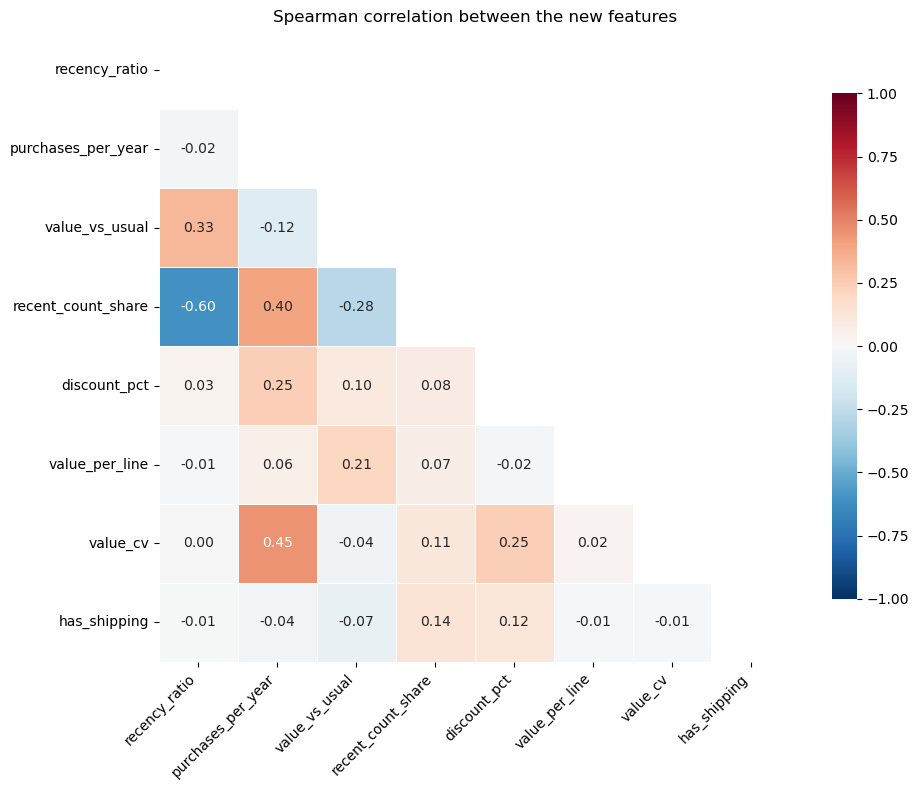

In [11]:
corr = df_dev[new_features].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))       # hide the upper half and the diagonal

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 10},
            cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8})
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.title("Spearman correlation between the new features")
plt.tight_layout()
plt.show()

No two new features are close copies of each other: the highest correlation is −0.60, between `recency_ratio` and `recent_count_share` (customers who are late compared to their usual rhythm made fewer purchases in the last 90 days). All new features bring different information.

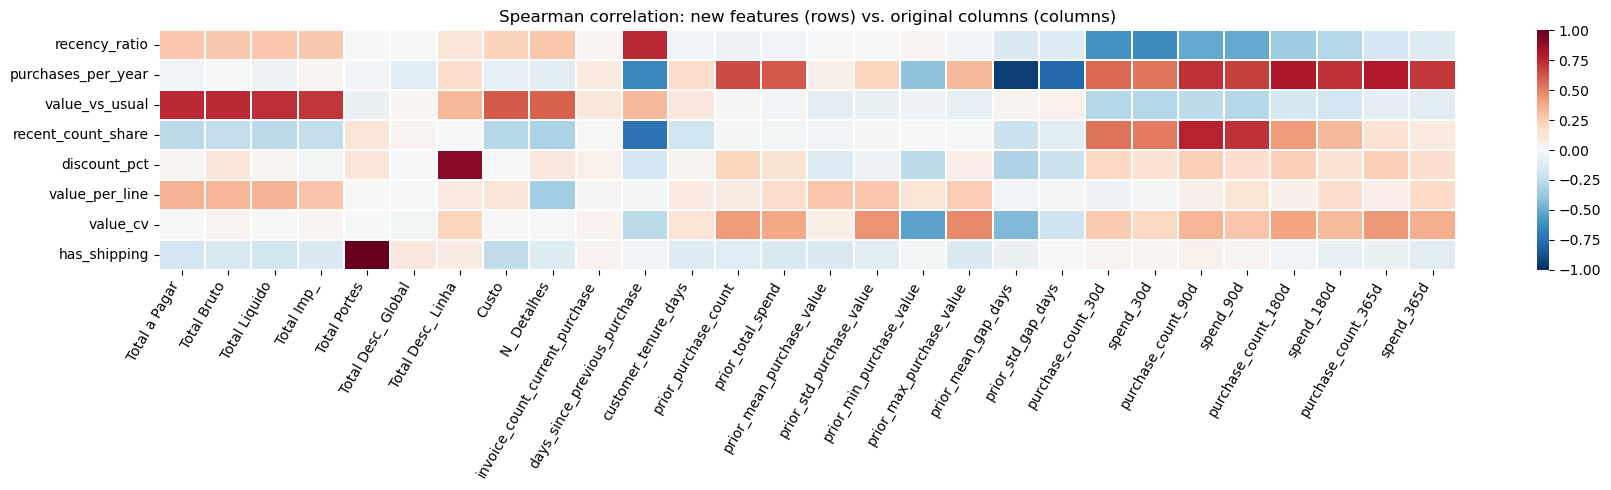

In [12]:
exclude = ["repeat_purchase_90d", "spend_next_90d", "ID", "customer_id", "random_noise"]
original_cols = [c for c in df_dev.select_dtypes(include="number").columns
                 if c not in exclude + new_features]

cross = (df_dev[new_features + original_cols]
         .corr(method="spearman")
         .loc[new_features, original_cols])

plt.figure(figsize=(18, 5))
sns.heatmap(cross, cmap="RdBu_r", vmin=-1, vmax=1, linewidths=0.3)
plt.xticks(rotation=60, ha="right")
plt.title("Spearman correlation: new features (rows) vs. original columns (columns)")
plt.tight_layout()
plt.show()

In [13]:
best = cross.abs().idxmax(axis=1)
top_match = pd.DataFrame({
    "most_similar_original": best,
    "spearman": [cross.loc[f, best[f]] for f in new_features],
}).round(2)
top_match

,most_similar_original,spearman
recency_ratio,days_since_previous_purchase,0.75
purchases_per_year,prior_mean_gap_days,-0.94
value_vs_usual,Total Bruto,0.75
recent_count_share,purchase_count_90d,0.77
discount_pct,Total Desc_ Linha,0.90
value_per_line,N_ Detalhes,-0.35
value_cv,prior_min_purchase_value,-0.53
has_shipping,Total Portes,0.99


Most new features are related to an original column (Spearman between 0.35 and 0.77) but add information, such as the customer's rhythm, tenure or history. Three are very close to an original column:
- `has_shipping` vs. `Total Portes` (0.99): since most purchases have no shipping costs, knowing *whether* there were shipping costs is practically the same as knowing *how much*.
- `purchases_per_year` vs. `prior_mean_gap_days` (−0.94): both measure the purchase rhythm (more purchases per year means fewer days between purchases).
- `discount_pct` vs. `Total Desc_ Linha` (0.90): largely driven by the many purchases with no discount (0 in both).

**Conclusions:**
- `has_shipping` **is dropped**: it is almost a copy of `Total Portes` and was also one of the weakest features.
- `purchases_per_year` is kept: it is also defined for customers with fewer than 2 previous purchases, where `prior_mean_gap_days` is missing, and it was one of the strongest features. The feature selection step will decide whether both are needed.
- `discount_pct` is kept: the EDA showed a clearer relationship with repeat purchase for the percentage than for the absolute discount.

In [14]:
# has_shipping is dropped: almost a copy of Total Portes (Spearman 0.99)
final_new_features = [f for f in new_features if f != "has_shipping"]
print(final_new_features)

['recency_ratio', 'purchases_per_year', 'value_vs_usual', 'recent_count_share', 'discount_pct', 'value_per_line', 'value_cv']


## Feature selection

In [15]:
# Development data only (before 2024), sorted by date so that the folds can use row positions
data = df_dev.sort_values("purchase_date").reset_index(drop=True)
y = data["repeat_purchase_90d"]

# Feature lists
not_features = ["repeat_purchase_90d", "spend_next_90d", "ID", "customer_id", "random_noise"]
original_numeric = [c for c in train_raw.select_dtypes(include="number").columns if c not in not_features]
categorical = []          # to be added once the encoding is decided

LOG_FEATURES = ["recency_ratio", "purchases_per_year", "value_vs_usual", "value_per_line"]
other_new = [f for f in final_new_features if f not in LOG_FEATURES]

print(len(original_numeric), "original numeric features")
print(len(final_new_features), "new features:", final_new_features)

28 original numeric features
7 new features: ['recency_ratio', 'purchases_per_year', 'value_vs_usual', 'recent_count_share', 'discount_pct', 'value_per_line', 'value_cv']


In [16]:
# Expanding-window folds: validate on 2020, 2021, 2022 and 2023, training on everything before.
# A training row is only used if its 90-day target window ends before the validation year starts.
def temporal_folds(dates, years=(2020, 2021, 2022, 2023), horizon_days=90):
    folds = []
    for year in years:
        start = pd.Timestamp(f"{year}-01-01")
        train_idx = np.where(dates + pd.Timedelta(days=horizon_days) < start)[0]
        val_idx = np.where(dates.dt.year == year)[0]
        folds.append((train_idx, val_idx))
    return folds

folds = temporal_folds(data["purchase_date"])
for year, (tr, va) in zip((2020, 2021, 2022, 2023), folds):
    print(f"fold {year}: train {len(tr)} rows, validation {len(va)} rows")

fold 2020: train 2578 rows, validation 670 rows
fold 2021: train 3234 rows, validation 782 rows
fold 2022: train 4004 rows, validation 628 rows
fold 2023: train 4705 rows, validation 767 rows


### Preprocessing (temporary)

The selectors need data without missing values and on comparable scales. This is a minimal, temporary preprocessing, applied inside the pipeline so it is re-fitted in each fold on training rows only:
- missing values are filled with the median, plus an indicator column marking where a value was missing;
- `log1p` is applied to the four long-tailed features;
- all columns are scaled with `RobustScaler`.

**Note:** `build_preprocessor()` is a simplified version. To use the group's preprocessing, replace this function (or import it from the project) and re-run the notebook: everything below uses it through the `"prep"` step, so nothing else needs to change.

In [25]:
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler

In [20]:
def build_preprocessor(numeric, log_numeric, categorical):
    """Temporary preprocessing: median imputation + missing indicators, log1p on long-tailed features, robust scaling."""
    num = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", RobustScaler()),
    ])
    log_num = Pipeline([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", RobustScaler()),
    ])
    transformers = [("num", num, numeric)]
    if log_numeric:
        transformers.append(("log", log_num, log_numeric))
    if categorical:                                   # ready for when the categorical features are added
        cat = Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)),
        ])
        transformers.append(("cat", cat, categorical))
    return ColumnTransformer(transformers, sparse_threshold=0)


# Columns used as input and the target
numeric_features = original_numeric + other_new
feature_columns = numeric_features + LOG_FEATURES + categorical
X = data[feature_columns]
print(len(feature_columns), "input columns")

35 input columns


In [21]:
train_idx, val_idx = folds[0]
prep = build_preprocessor(numeric_features, LOG_FEATURES, categorical)
X_train_prep = prep.fit_transform(X.iloc[train_idx], y.iloc[train_idx])

print("Shape after preprocessing:", X_train_prep.shape)
print("Missing values after preprocessing:", np.isnan(X_train_prep).sum())     # must be 0
print("Some column names:", list(prep.get_feature_names_out()[:5]))

Shape after preprocessing: (2578, 47)
Missing values after preprocessing: 0
Some column names: ['num__Total a Pagar', 'num__Total Bruto', 'num__Total Liquido', 'num__Total Imp_', 'num__Total Portes']


## Selectors

One selector of each kind, as in class:
- **Filter:** `SelectKBest(f_classif)`, which scores each feature alone against the target and keeps the best `k`.
- **Wrapper:** `RFE` with a logistic regression, which repeatedly drops the weakest features (10% at a time) until `k` are left.
- **Embedded:** `SelectFromModel` with a random forest, which keeps the features with above-average importance.
- **Combined:** the `VoteSelector` from class: a random forest, gradient boosting and an L1 logistic regression vote, and features with at least 2 of the 3 votes are kept.

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import roc_auc_score

train_idx, val_idx = folds[-1]                 # validate on 2023, train on everything before
X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

prep = build_preprocessor(numeric_features, LOG_FEATURES, categorical)
columns = pd.Index(prep.fit(X_train).get_feature_names_out())   # learned on train only
X_train_p = pd.DataFrame(prep.transform(X_train), columns=columns)
X_val_p = pd.DataFrame(prep.transform(X_val), columns=columns)

print("train:", X_train_p.shape, "| validation:", X_val_p.shape)

train: (4705, 47) | validation: (767, 47)


In [29]:
def train_and_score(cols):
    """Random forest trained on the given columns, ROC-AUC on 2023."""
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1)
    rf.fit(X_train_p[cols], y_train)
    return roc_auc_score(y_val, rf.predict_proba(X_val_p[cols])[:, 1])

selector_results = {"no selection": {"roc_auc": train_and_score(columns), "n_features": len(columns)}}
print(f"All {len(columns)} columns: ROC-AUC = {selector_results['no selection']['roc_auc']:.3f}")

All 47 columns: ROC-AUC = 0.786


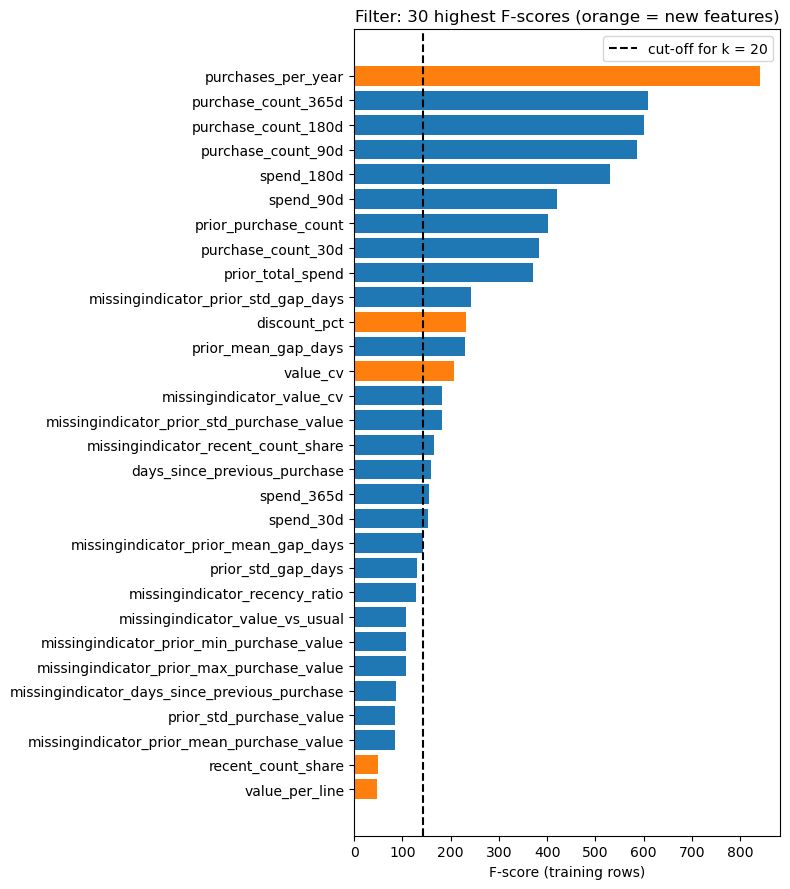

In [30]:
K = 20
f_scores = pd.Series(SelectKBest(f_classif, k="all").fit(X_train_p, y_train).scores_, index=columns)
f_scores.index = f_scores.index.str.replace(r"^\w+?__", "", regex=True)     # "num__Custo" -> "Custo"
f_scores = f_scores.sort_values()

top = f_scores.tail(30)
colors = ["tab:orange" if c in final_new_features else "tab:blue" for c in top.index]
cut = f_scores.sort_values(ascending=False).iloc[K - 1]

plt.figure(figsize=(8, 9))
plt.barh(top.index, top.values, color=colors)
plt.axvline(cut, color="black", linestyle="--", label=f"cut-off for k = {K}")
plt.xlabel("F-score (training rows)")
plt.title("Filter: 30 highest F-scores (orange = new features)")
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
for k in [10, 20, 30]:
    selector = SelectKBest(f_classif, k=k).fit(X_train_p, y_train)       # chosen on train only
    kept = columns[selector.get_support()]
    selector_results[f"filter (k={k})"] = {"roc_auc": train_and_score(kept), "n_features": k,
                                           "kept": list(kept)}

print(pd.DataFrame(selector_results).T[["roc_auc", "n_features"]])

kept_20 = [c.split("__", 1)[1] for c in selector_results["filter (k=20)"]["kept"]]
print("\nNew features kept (k=20):", [c for c in kept_20 if c in final_new_features])

                roc_auc n_features
no selection   0.785815       47.0
filter (k=10)  0.780489         10
filter (k=20)  0.787083         20
filter (k=30)  0.782909         30

New features kept (k=20): ['discount_pct', 'value_cv', 'purchases_per_year']


**Conclusions:** with 20 of the 47 columns, the filter keeps the same performance (ROC-AUC 0.787 vs. 0.786 with all columns), so the model becomes much simpler without losing anything. With only 10 columns there is a small loss (0.780). The differences between `k` values are very small and, with a single validation year, within noise.

Three new features are among the 20 kept: `discount_pct`, `value_cv` and `purchases_per_year`, three of the four strongest in the quintile analysis. The fourth, `recent_count_share`, is left out: its relationship with repeat purchase is an inverted U, and the F-test only detects differences in averages (linear relationships), so it underestimates it. This is the main limitation of a filter.